In [1]:
import pandas as pd
import numpy as np

In [15]:
path = "../../../TorgName Test.csv"
df = pd.read_csv(path, sep=';', header=None, decimal=',')
df.head()

,0,1,2,3,4,5,6,7
0,FOPBroshenskaOD,1,UKR,5499,Miscellaneous food stores,FOOD STORES-WAREHOUSE,17,3226.0
1,BushidoSushi,1,UKR,5814,Fast food res.,RESTAURANTS-BARS,6,4627.0
2,NIKOM,1,UKR,7629,Electrical & small appl.repa,REPAIR SHOPS,14,3775.9
3,LIQPAY*Romanyuk SG,1,UKR,5812,"Eating places,Restaurants",RESTAURANTS-BARS,1,670.0
4,MUeLLER WIEN 1-3 ECC,1,AUT,5912,"Drug stores,pharmacies",DRUG STORES,3,6696.4


In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 423757 entries, 0 to 423756
Data columns (total 8 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   0       423751 non-null  str    
 1   1       423757 non-null  int64  
 2   2       423748 non-null  str    
 3   3       423757 non-null  int64  
 4   4       423757 non-null  str    
 5   5       423757 non-null  str    
 6   6       423757 non-null  int64  
 7   7       423757 non-null  float64
dtypes: float64(1), int64(3), str(4)
memory usage: 25.9 MB


In [17]:
# Rename columns for clarity based on previous inspection
df.columns = ['Company_Name', 'Col1', 'Country', 'MCC', 'MCC_Description', 'Business_Category', 'Transactions_Count', 'Total_Volume']

Grouped_Name
GOOGLE        11301
EVA            1770
SILPO           324
APPLE           187
ZARA            147
ATB             143
BOLT            120
UBER            107
MAGAZIN         100
MCDONALDS        88
FORA             88
MAHAZYN          69
AMAZON           69
KFC              63
MINIMARKET       58
Name: count, dtype: int64


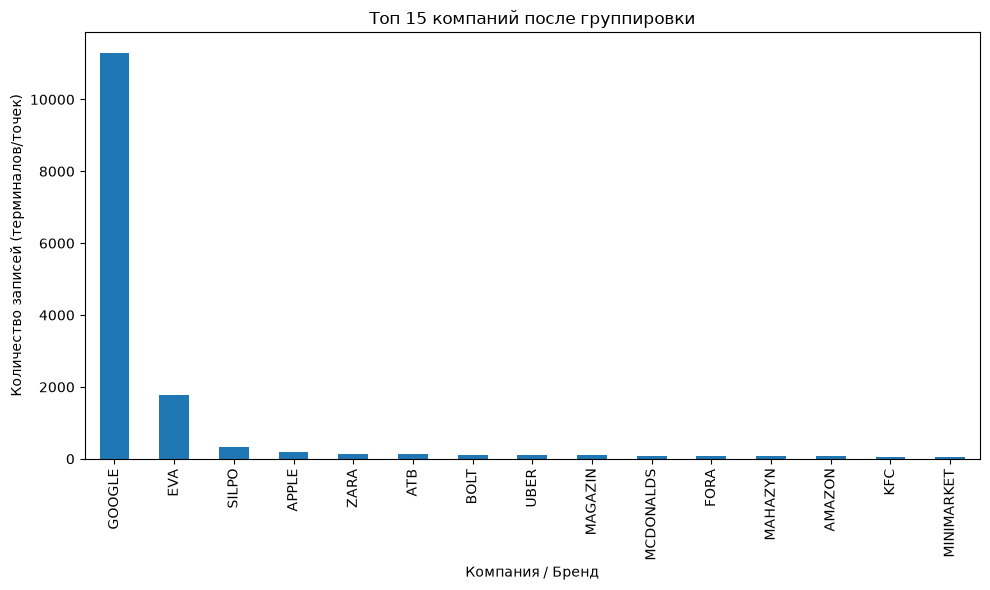

In [19]:
import re
import matplotlib.pyplot as plt

def extract_brand(name):
    name = str(name).upper()
    # Brands dictionary (simplified)
    brands = ['SILPO', 'ATB', 'NOVUS', 'MCDONALDS', 'KFC', 'ZARA', 'UBER', 'BOLT', 'UKLON', 'EVA', 'ROZETKA', 'WOG', 'OKKO', 'LIDL', 'CARREFOUR', 'AMAZON', 'ALIEXPRESS', 'APPLE', 'GOOGLE']
    for b in brands:
        if b in name:
            return b
            
    # If not a recognized brand, clean it up
    name = re.sub(r'^(LIQPAY|WAYFORPAY|PORTMONE|FONDY|WFP|EASYPAY|IPAY)[*_\-\s]*', '', name)
    name = re.sub(r'\b(FOP|TOV|PP|OOO|LLC|LTD|AT|ZAT|PAT|PRAT)\b', '', name)
    name = re.sub(r'[^A-ZА-Я0-9]', '', name)
    
    if name == '':
        return 'UNKNOWN'
    return name

df['Grouped_Name'] = df['Company_Name'].apply(extract_brand)

top_groups = df['Grouped_Name'].value_counts().head(15)

plt.figure(figsize=(10, 6))
top_groups.plot(kind='bar')
plt.title('Топ 15 компаний после группировки')
plt.xlabel('Компания / Бренд')
plt.ylabel('Количество записей (терминалов/точек)')
plt.tight_layout()
plt.savefig('top_companies.png')

print(top_groups)

MCC_Description
Miscellaneous food stores       56471
Eating places,Restaurants       40272
Fast food res.                  37417
Grocery stores,supermarkets     30071
Drug stores,pharmacies          19094
Family Clothing Stores           9871
Miscellaneous general mercha     9772
Service stations                 9018
Cosmetic stores                  7443
Beauty shops & barber shops      7181
Name: count, dtype: int64


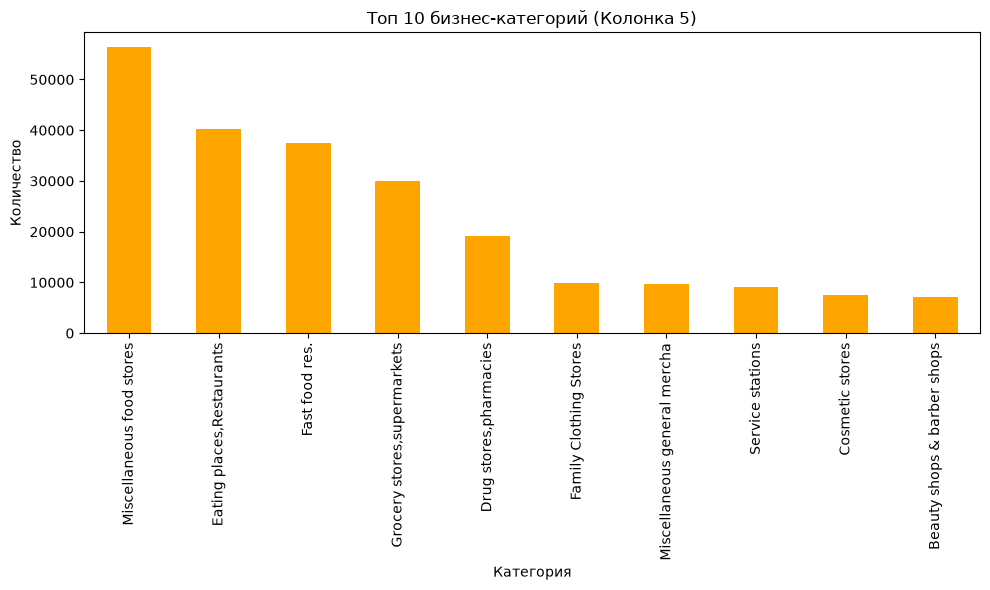

In [21]:
# Business categories
categories = df['MCC_Description'].value_counts().head(10)
plt.figure(figsize=(10, 6))
categories.plot(kind='bar', color='orange')
plt.title('Топ 10 бизнес-категорий (Колонка 5)')
plt.xlabel('Категория')
plt.ylabel('Количество')
plt.tight_layout()
plt.savefig('top_categories.png')
print(categories)

In [22]:
# Clean the numerical column 'Total_Volume' (replace comma with dot and convert to float)
df['Total_Volume'] = df['Total_Volume'].astype(str).str.replace(' ', '').str.replace(',', '.').astype(float)
df['Transactions_Count'] = pd.to_numeric(df['Transactions_Count'], errors='coerce').fillna(0)

# Group by Business_Category (Col 5) and MCC_Description (Col 4)
grouped_df = df.groupby(['Business_Category', 'MCC', 'MCC_Description']).agg(
    Terminals_Count=('Company_Name', 'count'),
    Total_Transactions=('Transactions_Count', 'sum'),
    Total_Volume=('Total_Volume', 'sum')
).reset_index()

# Sort by number of terminals descending
grouped_df = grouped_df.sort_values(by='Terminals_Count', ascending=False)

# Save the result to a new CSV file
output_filename = 'Grouped_by_Category_MCC.csv'
grouped_df.to_csv(output_filename, index=False, encoding='utf-8-sig', sep=';')

# Print the top 10 rows to show the user
print(grouped_df.head(10).to_string())

         Business_Category   MCC               MCC_Description  Terminals_Count  Total_Transactions  Total_Volume
103  FOOD STORES-WAREHOUSE  5499     Miscellaneous food stores            56471             4158497  1.094505e+09
384       RESTAURANTS-BARS  5812     Eating places,Restaurants            40271              359355  2.462753e+08
386       RESTAURANTS-BARS  5814                Fast food res.            37417              721798  2.091568e+08
98   FOOD STORES-WAREHOUSE  5411   Grocery stores,supermarkets            30071             3112030  1.367038e+09
86             DRUG STORES  5912        Drug stores,pharmacies            19094             1088279  3.541838e+08
72         CLOTHING STORES  5651        Family Clothing Stores             9871              167429  2.288032e+08
233           OTHER RETAIL  5399  Miscellaneous general mercha             9772              279161  1.731431e+08
104           GAS STATIONS  5541              Service stations             9018         

In [23]:
grouped_df_by_volume = grouped_df.sort_values(by='Total_Volume', ascending=False)
print(grouped_df_by_volume.head(10).to_string())

         Business_Category   MCC               MCC_Description  Terminals_Count  Total_Transactions  Total_Volume
98   FOOD STORES-WAREHOUSE  5411   Grocery stores,supermarkets            30071             3112030  1.367038e+09
103  FOOD STORES-WAREHOUSE  5499     Miscellaneous food stores            56471             4158497  1.094505e+09
86             DRUG STORES  5912        Drug stores,pharmacies            19094             1088279  3.541838e+08
104           GAS STATIONS  5541              Service stations             9018              381196  3.390275e+08
278         OTHER SERVICES  4215  Courier services-air or grou              465              156067  2.475186e+08
384       RESTAURANTS-BARS  5812     Eating places,Restaurants            40271              359355  2.462753e+08
72         CLOTHING STORES  5651        Family Clothing Stores             9871              167429  2.288032e+08
386       RESTAURANTS-BARS  5814                Fast food res.            37417         

Business_Category
HOTEL-MOTEL              76
OTHER SERVICES           70
AIRLINE                  52
OTHER RETAIL             45
RECREATION               20
VEHICLES                 17
HEALTH CARE              14
PROFESSIONAL SERVICES    13
CLOTHING STORES          12
AUTO RENTAL              12
Name: count, dtype: int64


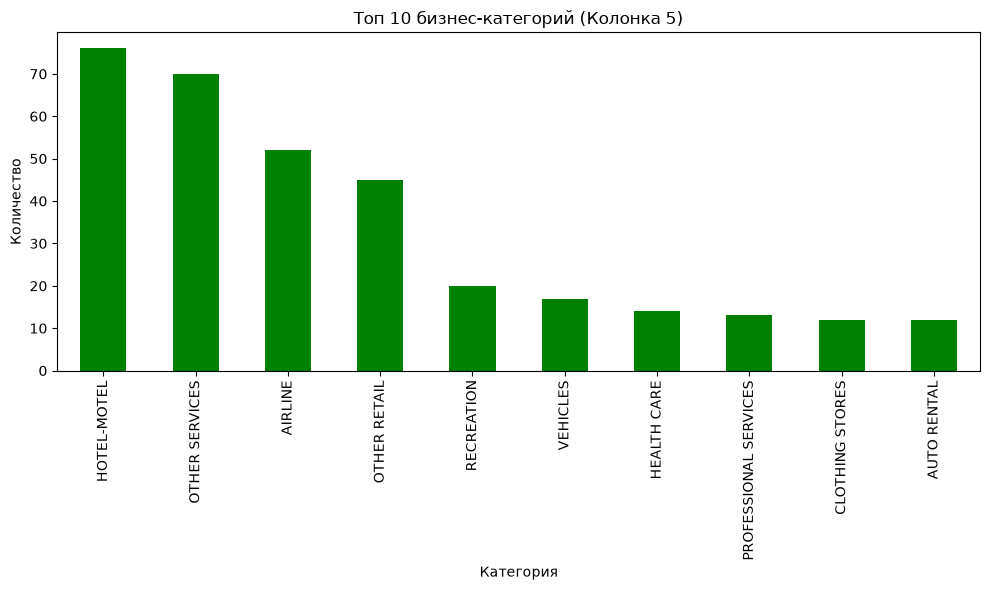

In [25]:
# Business categories
categories = grouped_df_by_volume['Business_Category'].value_counts().head(10)
plt.figure(figsize=(10, 6))
categories.plot(kind='bar', color='green')
plt.title('Топ 10 бизнес-категорий (Колонка 5)')
plt.xlabel('Категория')
plt.ylabel('Количество')
plt.tight_layout()
print(categories)

In [27]:
import pandas as pd
import re

df['Transactions_Count'] = pd.to_numeric(df['Transactions_Count'], errors='coerce').fillna(0)

# Extensive brand dictionary
brand_mapping = {
    'SILPO': ['SILPO', 'СІЛЬПО'],
    'ATB': ['ATB', 'АТБ'],
    'NOVUS': ['NOVUS', 'НОВУС'],
    'VARUS': ['VARUS', 'ВАРУС'],
    'METRO': ['METRO', 'МЕТРО'],
    'AUCHAN': ['AUCHAN', 'ASHAN', 'АШАН'],
    'FORA': ['FORA', 'ФОРА'],
    'TAVRIA V': ['TAVRIA V', 'TAVRIAV', 'ТАВРІЯ В', 'ТАВРИЯ В'],
    'MCDONALDS': ['MCDONALDS', 'MC DONALDS', 'МАКДОНАЛЬДС'],
    'KFC': ['KFC', 'КФС'],
    'ZARA': ['ZARA', 'ЗАРА'],
    'UBER': ['UBER', 'УБЕР'],
    'BOLT': ['BOLT', 'БОЛТ'],
    'UKLON': ['UKLON', 'УКЛОН'],
    'EVA': ['EVA', 'ЕВА', 'ЄВА'],
    'PROSTOR': ['PROSTOR', 'ПРОСТОР'],
    'WATSONS': ['WATSONS'],
    'ROZETKA': ['ROZETKA', 'РОЗЕТКА'],
    'EPICENTR': ['EPICENTR', 'EPITSENTR', 'ЕПІЦЕНТР'],
    'COMFY': ['COMFY', 'КОМФІ'],
    'FOXTROT': ['FOXTROT', 'ФОКСТРОТ'],
    'ALLO': ['ALLO', 'АЛЛО'],
    'CITRUS': ['CITRUS', 'ЦИТРУС'],
    'WOG': ['WOG', 'ВОГ'],
    'OKKO': ['OKKO', 'ОККО'],
    'SOCAR': ['SOCAR', 'СОКАР'],
    'KLO': ['KLO', 'КЛО'],
    'UPG': ['UPG', 'ЮПІДЖІ'],
    'BRSM': ['BRSM', 'БРСМ'],
    'SHELL': ['SHELL', 'ШЕЛЛ'],
    'AVIAS': ['AVIAS', 'АВІАС'],
    'LIDL': ['LIDL', 'ЛІДЛ'],
    'CARREFOUR': ['CARREFOUR'],
    'AMAZON': ['AMAZON', 'АМАЗОН'],
    'ALIEXPRESS': ['ALIEXPRESS', 'ALI EXPRESS', 'АЛІЕКСПРЕС'],
    'APPLE': ['APPLE', 'ITUNES'],
    'GOOGLE': ['GOOGLE', 'YOUTUBE'],
    'NOVA POSHTA': ['NOVAPOSHTA', 'NOVA POSHTA', 'НОВА ПОШТА'],
    'UKRPOSHTA': ['UKRPOSHTA', 'УКРПОШТА'],
    'KYIVSTAR': ['KYIVSTAR', 'КИЇВСТАР'],
    'VODAFONE': ['VODAFONE', 'ВОДАФОН'],
    'LIFECELL': ['LIFECELL', 'ЛАЙФСЕЛ'],
    'MEGOGO': ['MEGOGO', 'МЕГОГО'],
    'STEAM': ['STEAMGAMES', 'STEAM'],
    'NETFLIX': ['NETFLIX'],
    'MAKEUP': ['MAKEUP', 'МЕЙКАП'],
    'JYSK': ['JYSK', 'ЮСК']
}

def clean_and_extract_brand(name):
    name_upper = str(name).upper()
    
    # Map explicit brands
    for brand, keywords in brand_mapping.items():
        for kw in keywords:
            if kw in name_upper:
                return brand
                
    # If not a known brand, clean the string
    cleaned = re.sub(r'^(LIQPAY|WAYFORPAY|PORTMONE|FONDY|WFP|EASYPAY|IPAY|CITY24|PLATIONLINE)[*_\-\s]*', '', name_upper)
    cleaned = re.sub(r'\b(FOP|TOV|PP|OOO|LLC|LTD|AT|ZAT|PAT|PRAT|SPD|ФОП|ТОВ|ПП|ПРАТ|ЗАТ)\b', '', cleaned)
    cleaned = re.sub(r'[^A-ZА-Я0-9]', '', cleaned)
    
    # Mask single letters or empty
    if len(cleaned) < 2:
        return 'OTHER_OR_UNRECOGNIZED'
    return cleaned

df['Brand_Name'] = df['Company_Name'].apply(clean_and_extract_brand)

grouped_brands = df.groupby('Brand_Name').agg(
    Terminals_Count=('Company_Name', 'count'),
    Total_Transactions=('Transactions_Count', 'sum'),
    Total_Volume=('Total_Volume', 'sum')
).reset_index()

grouped_brands = grouped_brands.sort_values(by='Total_Volume', ascending=False)

# Filter out the generic ones to see actual grouped names
top_25 = grouped_brands[~grouped_brands['Brand_Name'].isin(['OTHER_OR_UNRECOGNIZED'])].head(25)

grouped_brands.to_csv('Grouped_by_Brands.csv', index=False, encoding='utf-8-sig', sep=';')

print(top_25.to_string())

        Brand_Name  Terminals_Count  Total_Transactions  Total_Volume
290552       SILPO              324              593661  3.228898e+08
26210          ATB              143              462515  2.270267e+08
107364        FORA              136              434878  1.856988e+08
231594     NOVAPAY                5              100427  1.482503e+08
231604  NOVAPOSHTA                4               53303  9.222684e+07
88270     EPICENTR               32               73727  7.928236e+07
317083    TAVRIYAV                8              142545  6.912111e+07
319401        TEMU                5               66448  6.076795e+07
90870          EVA             1767              128467  5.898486e+07
209993       METRO              328               28245  5.699159e+07
327474       TRASH                4              168505  4.698810e+07
337140       VARUS               15              104536  4.234464e+07
92154     FACEBOOK                4               10463  4.214018e+07
235324        OKKO  